# Análisis Post-Mortem: Wolf Sheep Predation

**Modelo:** Wolf Sheep Predation (NetLogo Library)

**Variante:** `sheep-wolves` (sin pasto)

**Parámetro analizado:** `initial-number-sheep` — número inicial de ovejas.

**Pregunta experimental:** ¿Cómo afecta el número inicial de ovejas al tiempo de duración de la simulación (ticks) en el modelo de depredación lobo-oveja?


## Variables del experimento

| Elemento | Valor |
|---|---|
| Variable independiente | `initial-number-sheep` (20, 40, 60, …, 200) |
| Variable dependiente final | `ticks` (tiempo hasta que la simulación termina) |
| Número de repeticiones | 30 por valor del parámetro (296 corridas válidas) |
| Condición de parada | No quedan turtles, o no quedan lobos y `count sheep > max-sheep` (30.000) |
| Archivo CSV | `wolfsheep_final.csv` |


In [ ]:
library(tidyverse)

## 1. Cargar datos

In [4]:
url <- "https://raw.githubusercontent.com/juandrodriguezf/wolf-sheep-predation-netlogo/master/wolf_sheep/wolfsheep_final.csv"
data <- read.csv(url, encoding = "UTF-8", skip = 6)

In [ ]:
head(data)
names(data)
glimpse(data)

,X.run.number.,initial.number.sheep,X.step.,ticks
,<int>,<int>,<int>,<int>
1,3,60,226,226
2,12,40,300,300
3,2,40,342,342
4,7,140,466,466
5,13,60,318,318
6,10,200,543,543


[1] "X.run.number."        "initial.number.sheep" "X.step."             
[4] "ticks"

Rows: 296
Columns: 4
$ X.run.number.        <int> 3, 12, 2, 7, 13, 10, 6, 9, 4, 14, 15, 16, 23, 22,…
$ initial.number.sheep <int> 60, 40, 40, 140, 60, 200, 120, 180, 80, 80, 100, …
$ X.step.              <int> 226, 300, 342, 466, 318, 543, 421, 444, 406, 454,…
$ ticks                <int> 226, 300, 342, 466, 318, 543, 421, 444, 406, 454,…


## 2. Renombrar columnas

In [ ]:
colnames(data) <- c("corrida", "parametro", "otra_columna", "resultado_final")
head(data)

,corrida,parametro,otra_columna,resultado_final
,<int>,<int>,<int>,<int>
1,3,60,226,226
2,12,40,300,300
3,2,40,342,342
4,7,140,466,466
5,13,60,318,318
6,10,200,543,543


## 3. Seleccionar columnas relevantes

In [7]:
datas <- data %>% select(parametro, resultado_final)
head(datas)

,parametro,resultado_final
,<int>,<int>
1,60,226
2,40,300
3,40,342
4,140,466
5,60,318
6,200,543


## 4. Gráfica de dispersión

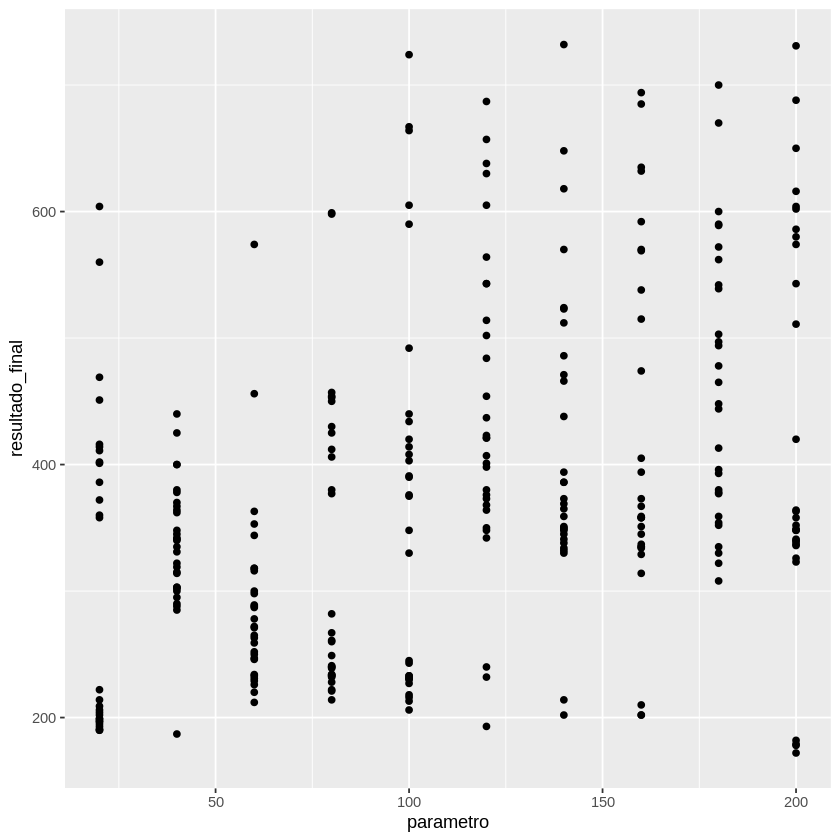

In [ ]:
datas %>%
  ggplot(aes(parametro, resultado_final)) +
  geom_point()

## 5. Dispersión con jitter y color

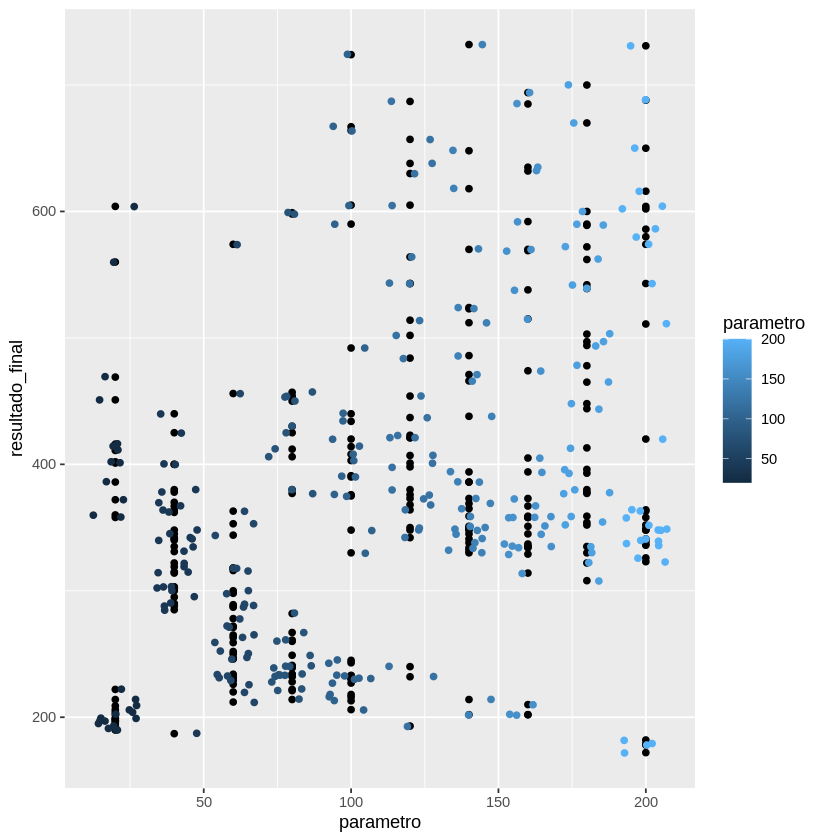

In [9]:
datas %>%
  ggplot(aes(parametro, resultado_final)) +
  geom_point() +
  geom_jitter(aes(color = parametro))

## 6. Boxplot por grupo

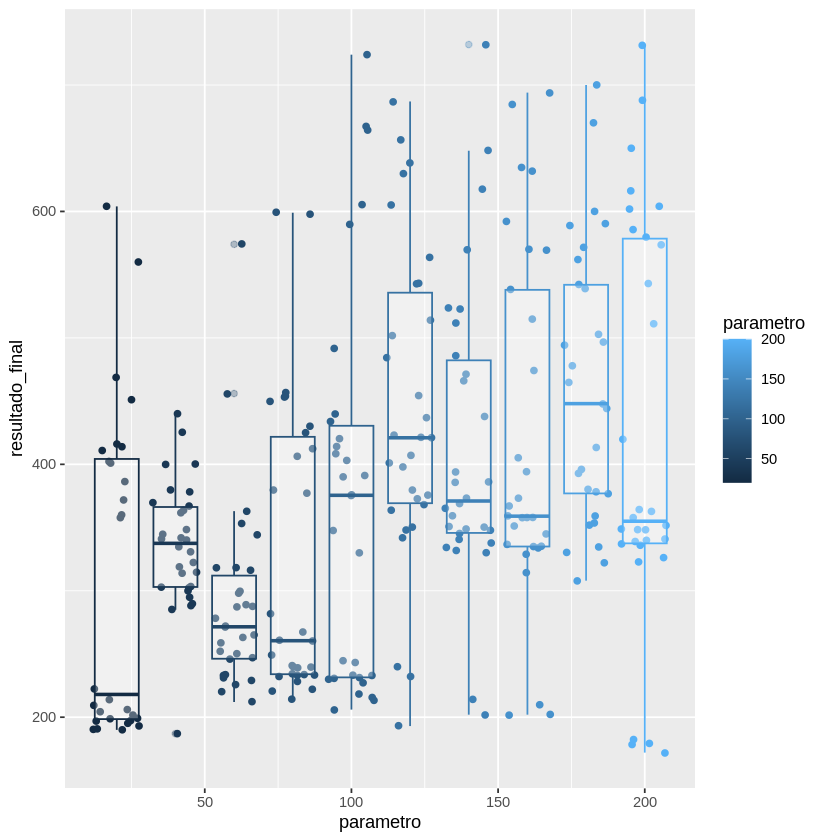

In [10]:
datas %>%
  ggplot(aes(parametro, resultado_final)) +
  geom_jitter(aes(color = parametro)) +
  geom_boxplot(aes(group = parametro, color = parametro), alpha = 0.3)

## 7. Interpretación

La gráfica de dispersión muestra el tiempo de simulación (`ticks`) en función del número inicial de ovejas (`initial-number-sheep`). Las medias van de 289.7 ticks (60 ovejas) a 461.7 (180), pero los rangos de todos los grupos se superponen: hay corridas que terminan cerca del tick 190 y otras que superan los 700 para casi cualquier valor.

**Tendencia general:** No se aprecia una tendencia monótona. Las medias más bajas corresponden a 60 (289.7) y 20 (307.6); las más altas a 180 (461.7) y 120 (443.2). A partir de 100 ovejas la media se mantiene entre 373 y 462 ticks, sin que 200 supere a 180. Los valores extremos aparecen en todo el rango: máximos en 140 (732), 200 (731) y 100 (724); mínimos en 200 (172), 40 (187) y 20 (190).

**Dos desenlaces:** `ticks` no distingue entre el colapso de las ovejas y el desborde en el que los lobos se extinguen y las ovejas superan `max-sheep` (30.000). El análisis evolutivo muestra que ambos ocurren y que tienen duraciones distintas; por eso la métrica final mezcla procesos y pierde poder explicativo.

**Variabilidad:** La dispersión es grande en todos los niveles del parámetro y los rangos intercuartílicos se superponen. El número inicial de ovejas no es el único determinante: la secuencia aleatoria de reproducciones, cazas y muertes produce trayectorias muy diferentes.

**Limitaciones:** Este notebook solo analiza el estado final (`ticks`). Para entender el mecanismo hay que revisar la evolución temporal en `WolfSheep_Evolutivo.ipynb`, donde se observan ciclos de crecimiento y colapso.
